# MLIP



| # | Exercise | Key idea |
|---|---|---|
| 1 | Argon dimer in real units, and choosing the finite-difference step $h$ | $\mathbf F=-\nabla E$ |
| 2 | Curvature of three cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ of a carbon atom in graphene | descriptor as a smooth RDF |
| 4 | $G^4$: separating the angular and radial parts | role of $\eta$ and $\lambda$ |

Exercise 1 uses eV and Å, exercises 2–4 use Å. Only NumPy and Matplotlib are needed.

---
## Exercise 1. Argon dimer in real units and the finite-difference step
Lennard-Jones argon: $\epsilon=0.0104$ eV, $\sigma=3.40$ Å,
$$U(r)=4\epsilon\big[(\sigma/r)^{12}-(\sigma/r)^6\big],\qquad F(r)=\frac{24\epsilon}{r}\big[2(\sigma/r)^{12}-(\sigma/r)^6\big].$$
The central difference has a **truncation error** $\propto h^2$ (too large $h$) and a **round-off error** $\propto\varepsilon_{\rm mach}/h$ (too small $h$). We scan $h$ to find the sweet spot.

U(3.6) = -8.571 meV,  F(3.6) = +0.02063 eV/A
best step h = 1.8e-06 A, error = 5.9e-13 eV/A


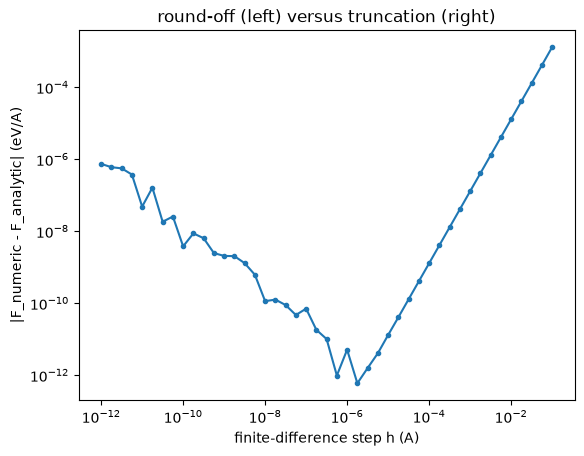

In [1]:
import numpy as np, matplotlib.pyplot as plt

eps, sig = 0.0104, 3.40                                   # eV, Angstrom
U = lambda r: 4 * eps * ((sig / r)**12 - (sig / r)**6)
F = lambda r: 24 * eps / r * (2 * (sig / r)**12 - (sig / r)**6)

r = 3.6                                                   # Angstrom, on the repulsive side of the minimum
print(f"U({r}) = {1000*U(r):.3f} meV,  F({r}) = {F(r):+.5f} eV/A")

hs = np.logspace(-12, -1, 45)
err = [abs(-(U(r + h) - U(r - h)) / (2 * h) - F(r)) for h in hs]
best = hs[np.argmin(err)]
print(f"best step h = {best:.1e} A, error = {min(err):.1e} eV/A")

plt.loglog(hs, err, "o-", ms=3)
plt.xlabel("finite-difference step h (A)"); plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.title("round-off (left) versus truncation (right)"); plt.show()

**Your turn.** Theory predicts the best step near $h\sim\varepsilon_{\rm mach}^{1/3}\times(\text{length scale})$ with $\varepsilon_{\rm mach}\approx2\times10^{-16}$. Does your optimum agree? Repeat with the forward difference $-[U(r+h)-U(r)]/h$. Where is its optimum, and why is it worse?

central : best h = 1.8e-06 A, min error = 5.9e-13 eV/A
forward : best h = 1.0e-08 A, min error = 5.5e-10 eV/A
eps_mach^(1/3) * sigma = 2.1e-05 A   (central-difference estimate)
eps_mach^(1/2) * sigma = 5.1e-08 A   (forward-difference estimate)


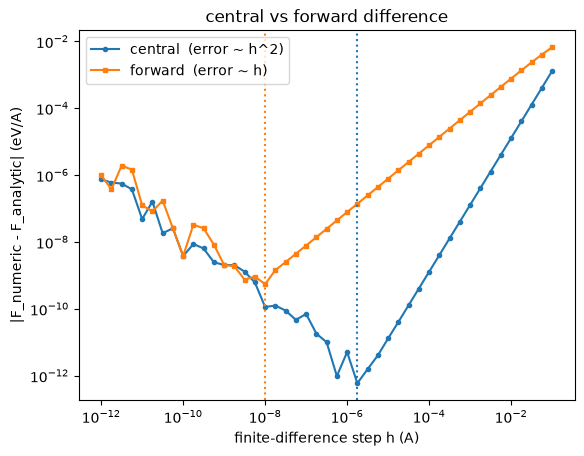

In [2]:
# Exercise 1 answer: central vs forward difference, scanned over h
import numpy as np, matplotlib.pyplot as plt
eps, sig = 0.0104, 3.40
U = lambda r: 4 * eps * ((sig / r)**12 - (sig / r)**6)
F = lambda r: 24 * eps / r * (2 * (sig / r)**12 - (sig / r)**6)
r = 3.6
hs = np.logspace(-12, -1, 45)
err_c = np.array([abs(-(U(r + h) - U(r - h)) / (2 * h) - F(r)) for h in hs])
err_f = np.array([abs(-(U(r + h) - U(r)) / h - F(r)) for h in hs])
hc, hf = hs[np.argmin(err_c)], hs[np.argmin(err_f)]
print(f"central : best h = {hc:.1e} A, min error = {err_c.min():.1e} eV/A")
print(f"forward : best h = {hf:.1e} A, min error = {err_f.min():.1e} eV/A")
eps_mach = np.finfo(float).eps
print(f"eps_mach^(1/3) * sigma = {eps_mach**(1/3) * sig:.1e} A   (central-difference estimate)")
print(f"eps_mach^(1/2) * sigma = {eps_mach**(1/2) * sig:.1e} A   (forward-difference estimate)")

plt.loglog(hs, err_c, "o-", ms=3, label="central  (error ~ h^2)")
plt.loglog(hs, err_f, "s-", ms=3, label="forward  (error ~ h)")
plt.axvline(hc, color="C0", ls=":"); plt.axvline(hf, color="C1", ls=":")
plt.xlabel("finite-difference step h (A)"); plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.legend(); plt.title("central vs forward difference"); plt.show()

**Answer (Exercise 1).**

*Central difference.* The scan gives an optimum at $h\approx 2\times10^{-6}$ Å with an error of only $\sim6\times10^{-13}$ eV/Å. The naive estimate $\varepsilon_{\rm mach}^{1/3}\sigma\approx2\times10^{-5}$ Å is within about one order of magnitude of this. It is not exact because the "length scale" in the theory is really $(U/U^{(3)})^{1/3}$, i.e. the distance over which the potential changes appreciably, and for the steep $r^{-12}$ repulsion this is several times shorter than $\sigma$. So the optimum agrees with $h\sim\varepsilon_{\rm mach}^{1/3}\times(\text{length})$ once the proper (smaller) local length scale is used. The trade-off is: truncation error $\sim h^2U^{(3)}/6$ (right side of the V) against round-off error $\sim\varepsilon_{\rm mach}|U|/h$ (left side).

*Forward difference.* Its optimum is at $h\approx10^{-8}$ Å, i.e. near $\varepsilon_{\rm mach}^{1/2}\times(\text{length})$, and the minimum error is only $\sim5\times10^{-10}$ eV/Å, about 3 orders of magnitude worse than the central difference. The reason is that the forward-difference truncation error is first order, $\approx hU''/2\propto h$ (the $O(h)$ term does not cancel because the stencil is not symmetric), while round-off is still $\sim\varepsilon_{\rm mach}/h$. Balancing $h$ against $\varepsilon/h$ gives $h_{\rm opt}\sim\sqrt{\varepsilon}$ and the best error $\sim\sqrt{\varepsilon}\sim10^{-8}$ (relative), whereas the central difference balances $h^2$ against $\varepsilon/h$, giving $h_{\rm opt}\sim\varepsilon^{1/3}$ and the best error $\sim\varepsilon^{2/3}\sim10^{-11}$ (relative). The symmetric stencil cancels the $O(h)$ term, so it can use a larger $h$ (smaller round-off) and still be accurate.

---
## Exercise 2. Curvature of three cutoff functions
For energy conservation, the force (first derivative) must be continuous. For vibrational properties and stable integration, the **second** derivative should also be smooth. Compare at $r_c=5$ Å
- cosine: $\tfrac12[\cos(\pi r/r_c)+1]$,
- MTP-style: $(1-r/r_c)^2$,
- polynomial envelope with $p=6$.

cosine        : just inside rc  f = 2.5e-06,  f' = -9.9e-04,  f'' = +0.197
(1 - r/rc)^2  : just inside rc  f = 1.0e-06,  f' = -4.0e-04,  f'' = +0.080
envelope p=6  : just inside rc  f = 5.6e-08,  f' = -3.4e-05,  f'' = +0.013


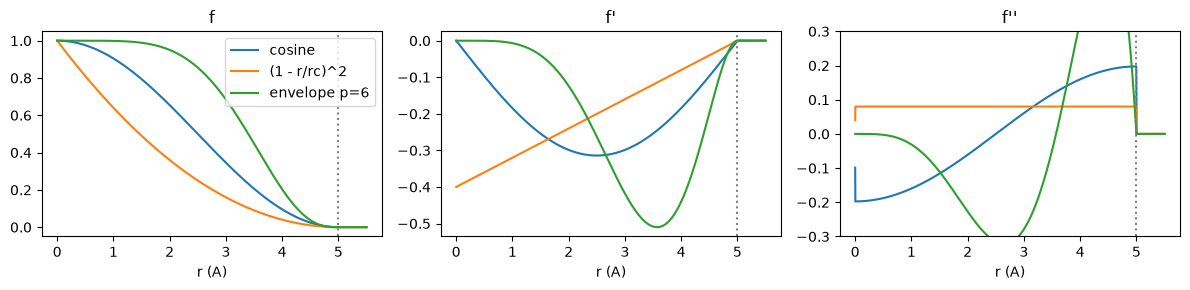

In [3]:
import numpy as np, matplotlib.pyplot as plt

rc = 5.0
r = np.linspace(0, 5.5, 5501); x = np.minimum(r / rc, 1)
cuts = {
    "cosine":       np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0),
    "(1 - r/rc)^2": np.where(r < rc, (1 - x)**2, 0),
    "envelope p=6": np.where(r < rc, 1 - 28 * x**6 + 48 * x**7 - 21 * x**8, 0),
}
dr = r[1] - r[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for name, f in cuts.items():
    d1 = np.gradient(f, dr); d2 = np.gradient(d1, dr)
    ax[0].plot(r, f, label=name); ax[1].plot(r, d1, label=name); ax[2].plot(r, d2, label=name)
    i = np.searchsorted(r, rc) - 5
    print(f"{name:14s}: just inside rc  f = {f[i]:.1e},  f' = {d1[i]:+.1e},  f'' = {d2[i]:+.3f}")
for a_, t in zip(ax, ("f", "f'", "f''")): a_.set_title(t); a_.axvline(rc, color="gray", ls=":"); a_.set_xlabel("r (A)")
ax[2].set_ylim(-0.3, 0.3); ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** Rank the three functions by smoothness at $r_c$ (value, slope, curvature). The cosine and $(1-r/r_c)^2$ both have zero slope but nonzero curvature at $r_c$, so the forces are continuous while their derivatives jump. Which property (energy conservation in MD, or phonon frequencies from the Hessian) is affected by a curvature jump, and why?

In [4]:
# Exercise 2 answer: size of the jumps at r_c, and the second derivative just inside r_c
import numpy as np
rc = 5.0
x = 1.0
# analytic values at x = r/rc -> 1^- (derivatives are with respect to r)
f2_cos = 0.5 * (np.pi / rc)**2          # f'' = -(1/2)(pi/rc)^2 cos(pi x) -> +(1/2)(pi/rc)^2
f2_quad = 2 / rc**2                      # f'' = 2/rc^2
f2_env = (-28*30 + 48*42 - 21*56) / rc**2  # polynomial: -28*6*5 x^4 + 48*7*6 x^5 - 21*8*7 x^6 -> 0 at x=1
print(f"cosine        : f''(rc-) = {f2_cos:.4f}   (jump to 0 at rc)")
print(f"(1-r/rc)^2    : f''(rc-) = {f2_quad:.4f}   (jump to 0 at rc)")
print(f"envelope p=6  : f''(rc-) = {f2_env:.4f}   (no jump)")

cosine        : f''(rc-) = 0.1974   (jump to 0 at rc)
(1-r/rc)^2    : f''(rc-) = 0.0800   (jump to 0 at rc)
envelope p=6  : f''(rc-) = 0.0000   (no jump)


**Answer (Exercise 2).**

*Ranking (smoothest first):*
1. **Polynomial envelope ($p=6$):** value, slope and curvature are all zero at $r_c$ ($f''(r_c)=0$ exactly, as the numbers above show), so it is $C^2$ at the cutoff.
2. **$(1-r/r_c)^2$:** value and slope vanish, but $f''(r_c^-)=2/r_c^2=0.08$ Å$^{-2}$, a jump in curvature (it is only $C^1$).
3. **Cosine:** value and slope vanish, but $f''(r_c^-)=\tfrac12(\pi/r_c)^2\approx0.197$ Å$^{-2}$. It is also only $C^1$ and its curvature jump is about 2.5 times larger than that of $(1-r/r_c)^2$.

*Which property is affected by a curvature jump?* **The phonon frequencies / Hessian.** The force is $F=-\nabla E$, so continuity of $E$ and its first derivative guarantees that $F$ is continuous. The energy is then a well-defined smooth function of positions to first order, and the force is a genuine gradient of that energy, so total energy is conserved in MD (only a small integration error appears when an atom crosses $r_c$, because $F'$ is discontinuous and the Verlet error constant is slightly degraded). The Hessian $\partial^2E/\partial r_i\partial r_j$, however, contains $f''$, so a curvature jump makes the force constants discontinuous: a pair crossing $r_c$ changes the dynamical matrix abruptly. This produces spurious steps/noise in phonon frequencies (and elastic constants), and the finite-difference Hessian of a structure with a neighbour close to $r_c$ is ill-defined or noisy. Smoother cutoffs such as the $p=6$ envelope avoid this.

---
## Exercise 3. Radial fingerprint of a carbon atom in graphene
$$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}).$$
In graphene ($d_{\rm CC}=1.42$ Å) each carbon has 3 first neighbours at 1.42 Å, 6 second neighbours at 2.46 Å and 3 third neighbours at 2.84 Å. We build a patch of the honeycomb lattice and compute the fingerprint of one atom.

shell at 1.420 A: 3 atoms
shell at 2.460 A: 6 atoms
shell at 2.840 A: 3 atoms


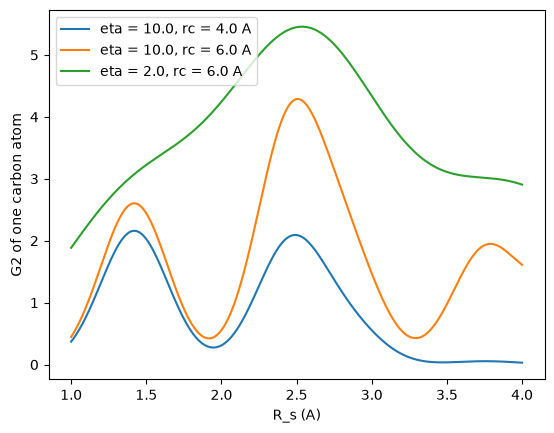

In [5]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

d = 1.42
a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])   # lattice vectors
basis = [np.zeros(2), np.array([d, 0.0])]                                           # two atoms per cell
atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
r0j = np.linalg.norm(atoms - centre, axis=1); r0j = r0j[r0j > 1e-6]
for s in np.unique(r0j[r0j < 3.0].round(3)):
    print(f"shell at {s:.3f} A: {np.sum(np.isclose(r0j, s, atol=1e-3))} atoms")

Rs = np.linspace(1.0, 4.0, 400)
for eta, rc in [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]:
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, rc)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}, rc = {rc} A")
plt.xlabel("R_s (A)"); plt.ylabel("G2 of one carbon atom"); plt.legend(); plt.show()

**Your turn.** Stretch the lattice by 2 % (multiply `d` by 1.02) and plot the difference in $G^2$. Where does the fingerprint change most? This is how an MLIP \"sees\" strain.

eta=10.0, rc=4.0: largest change -0.335 at R_s = 2.30 A (G2 there = 1.54)
eta=10.0, rc=6.0: largest change -0.585 at R_s = 2.29 A (G2 there = 2.91)
eta= 2.0, rc=6.0: largest change -0.303 at R_s = 2.18 A (G2 there = 4.80)


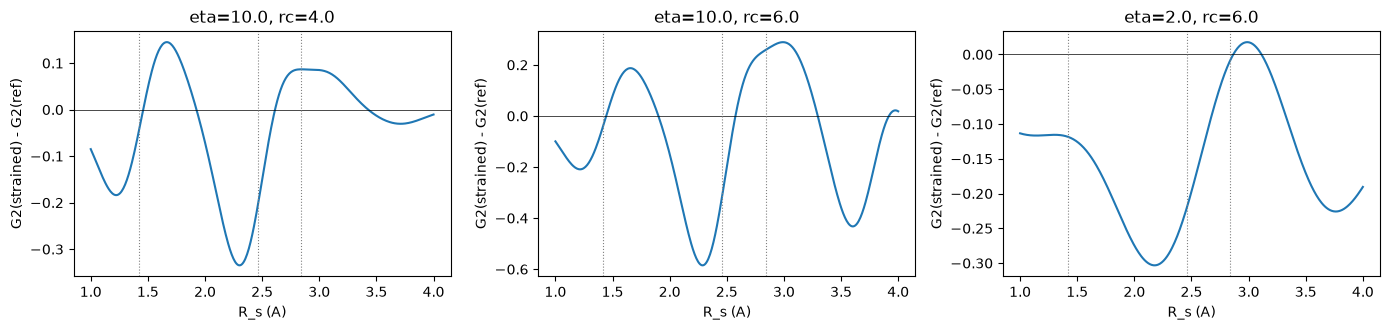

In [6]:
# Exercise 3 answer: effect of 2 % strain on G2
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

def distances(d):
    a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])
    basis = [np.zeros(2), np.array([d, 0.0])]
    atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
    centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
    r0j = np.linalg.norm(atoms - centre, axis=1)
    return r0j[r0j > 1e-6]

Rs = np.linspace(1.0, 4.0, 400)
r_ref, r_str = distances(1.42), distances(1.42 * 1.02)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4), sharey=False)
for a, (eta, rc) in zip(ax, [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]):
    G = lambda r0: np.array([np.sum(np.exp(-eta * (r0 - s)**2) * fc(r0, rc)) for s in Rs])
    g0, g1 = G(r_ref), G(r_str)
    dG = g1 - g0
    a.plot(Rs, dG); a.axhline(0, color="k", lw=0.5)
    for s in (1.42, 2.46, 2.84): a.axvline(s, color="gray", ls=":", lw=0.8)
    a.set_title(f"eta={eta}, rc={rc}"); a.set_xlabel("R_s (A)"); a.set_ylabel("G2(strained) - G2(ref)")
    i = np.argmax(np.abs(dG))
    print(f"eta={eta:4.1f}, rc={rc}: largest change {dG[i]:+.3f} at R_s = {Rs[i]:.2f} A (G2 there = {g0[i]:.2f})")
plt.tight_layout(); plt.show()

**Answer (Exercise 3).**

The difference $G^2_{\rm strained}-G^2_{\rm ref}$ is **not** largest at the peaks themselves (the shells at 1.42, 2.46, 2.84 Å, dotted lines) but on their **flanks**: it has a $+/-$ (derivative-like) shape around each shell. Shifting a Gaussian of width $1/\sqrt{2\eta}$ by $\delta$ changes it by $\approx -\delta\,\partial_{R_s}G^2$, which is zero at the top of the peak and maximal on the slopes. A 2 % stretch moves the shells by $+0.028$ Å (first), $+0.049$ Å (second) and $+0.057$ Å (third), so the larger the distance, the larger the shift.

For $\eta=10$ the largest change is on the slopes of the **second-neighbour shell** (largest magnitude, $\approx0.3$–$0.6$ at $R_s\approx2.3$ Å), because that shell has 6 atoms (twice as many as the first and third shells) and moves further than the first shell. There are also clear changes near 1.2 and 1.65 Å (flanks of the first-neighbour shell, shifted by $+0.03$ Å) and on the third shell near 2.9 Å. A larger cutoff ($r_c=6$) enlarges the signal, since the cutoff function damps these shells less. For the broad $\eta=2$ function the response is smaller and smoother, as the wide Gaussians blur the shells together and a small shift hardly changes them.

So the MLIP "sees" strain as a systematic change of the fingerprint at specific radii: narrow Gaussians (large $\eta$) resolve small bond-length changes, with sensitivity $\propto\sqrt{\eta}\times$(shift)$\times$(coordination number), while wide ones (small $\eta$) give a smoother, less sensitive descriptor.

---
## Exercise 4. $G^4$: separating the angular and radial parts
For a symmetric triplet with bond length $b$ and angle $\theta$, $r_{jk}=2b\sin(\theta/2)$ and
$$G^4=\underbrace{2^{1-\zeta}(1+\lambda\cos\theta)^\zeta}_{\text{angular}}\;\underbrace{e^{-\eta(2b^2+r_{jk}^2)}}_{\text{radial}}\;f_c(b)^2f_c(r_{jk}).$$
Because $r_{jk}$ depends on $\theta$, the radial part also carries angular information. We see how $\eta$ reshapes $G^4(\theta)$ for $b=1.42$ Å (a C–C bond).

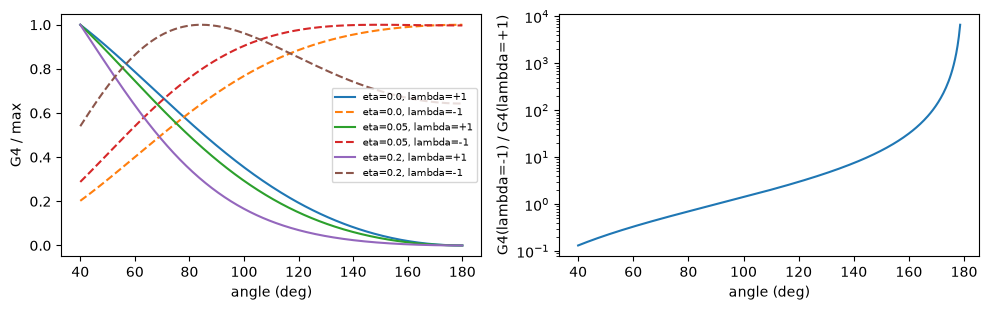

 90.0 deg: ratio =  1.000  -> recovered angle 90.0 deg
109.5 deg: ratio =  2.002  -> recovered angle 109.5 deg
120.0 deg: ratio =  3.000  -> recovered angle 120.0 deg
150.0 deg: ratio = 13.928  -> recovered angle 150.0 deg


In [7]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)
b, rc = 1.42, 6.0
theta = np.linspace(40, 180, 300); t = np.deg2rad(theta)
rjk = 2 * b * np.sin(t / 2)

def G4(zeta, lam, eta):
    return 2**(1 - zeta) * (1 + lam * np.cos(t))**zeta * np.exp(-eta * (2 * b**2 + rjk**2)) * fc(b, rc)**2 * fc(rjk, rc)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for eta in (0.0, 0.05, 0.2):
    for lam, st in ((1, "-"), (-1, "--")):
        g = G4(1, lam, eta)
        ax[0].plot(theta, g / g.max(), st, label=f"eta={eta}, lambda={lam:+d}")
ax[0].set_xlabel("angle (deg)"); ax[0].set_ylabel("G4 / max"); ax[0].legend(fontsize=7)

g_plus, g_minus = G4(1, 1, 0.05), G4(1, -1, 0.05)
ok = theta < 179                                     # G4(lambda=+1) = 0 at exactly 180 deg
ax[1].plot(theta[ok], g_minus[ok] / g_plus[ok]); ax[1].set_yscale("log")
ax[1].set_xlabel("angle (deg)"); ax[1].set_ylabel("G4(lambda=-1) / G4(lambda=+1)")
plt.tight_layout(); plt.show()

for th in (90.0, 109.5, 120.0, 150.0):
    c = np.cos(np.deg2rad(th))
    ratio = (1 - c) / (1 + c)                           # tan^2(theta/2); diverges only at exactly 180 deg
    print(f"{th:5.1f} deg: ratio = {ratio:6.3f}  -> recovered angle {2 * np.degrees(np.arctan(np.sqrt(ratio))):.1f} deg")

**Your turn.** With $\eta=0.2$ the $\lambda=-1$ curve no longer peaks at $180^\circ$ but near $85^\circ$. Explain this shift from the $e^{-\eta r_{jk}^2}$ factor (which angles give a long $r_{jk}$?). Why does the ratio $G^4(\lambda=-1)/G^4(\lambda=+1)$ not depend on $\eta$ at all?

lambda=-1, eta=0.00: maximum at theta = 180.0 deg
lambda=-1, eta=0.05: maximum at theta = 149.3 deg
lambda=-1, eta=0.20: maximum at theta = 84.4 deg
eta=0.00: max deviation from tan^2(theta/2) = 1.77e-09
eta=0.05: max deviation from tan^2(theta/2) = 1.77e-09
eta=0.20: max deviation from tan^2(theta/2) = 1.77e-09
eta=1.00: max deviation from tan^2(theta/2) = 1.77e-09


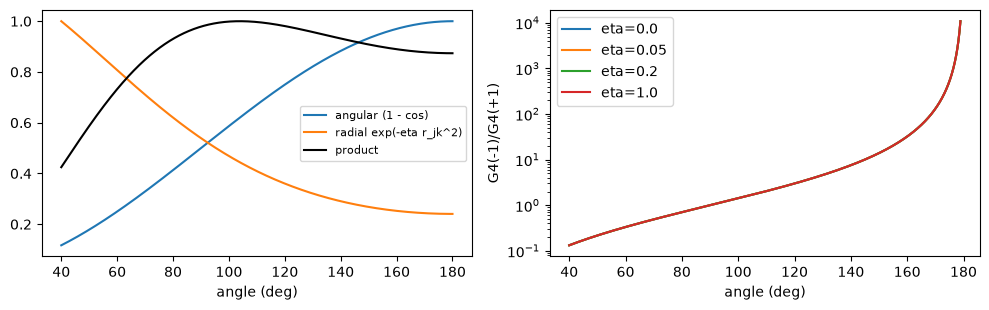

In [8]:
# Exercise 4 answer: location of the lambda=-1 maximum and eta-independence of the ratio
import numpy as np, matplotlib.pyplot as plt
fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)
b, rc = 1.42, 6.0
theta = np.linspace(40, 180, 1401); t = np.deg2rad(theta)
rjk = 2 * b * np.sin(t / 2)
def G4(zeta, lam, eta):
    return 2**(1 - zeta) * (1 + lam * np.cos(t))**zeta * np.exp(-eta * (2 * b**2 + rjk**2)) * fc(b, rc)**2 * fc(rjk, rc)

for eta in (0.0, 0.05, 0.2):
    g = G4(1, -1, eta)
    print(f"lambda=-1, eta={eta:4.2f}: maximum at theta = {theta[np.argmax(g)]:.1f} deg")

# ratio for several eta: identical curves
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ok = theta < 179
for eta in (0.0, 0.05, 0.2, 1.0):
    ratio = G4(1, -1, eta)[ok] / G4(1, 1, eta)[ok]
    ax[1].plot(theta[ok], ratio, label=f"eta={eta}")
    print(f"eta={eta:4.2f}: max deviation from tan^2(theta/2) = {np.max(np.abs(ratio - np.tan(t[ok] / 2)**2)):.2e}")
ax[1].set_yscale("log"); ax[1].set_xlabel("angle (deg)"); ax[1].set_ylabel("G4(-1)/G4(+1)"); ax[1].legend()
# the three factors for lambda=-1, eta = 0.2
ang = (1 - np.cos(t)); rad = np.exp(-0.2 * (2 * b**2 + rjk**2))
ax[0].plot(theta, ang / ang.max(), label="angular (1 - cos)"); ax[0].plot(theta, rad / rad.max(), label="radial exp(-eta r_jk^2)")
ax[0].plot(theta, ang * rad / (ang * rad).max(), "k", label="product")
ax[0].set_xlabel("angle (deg)"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Answer (Exercise 4).**

*Why the $\lambda=-1$ maximum moves from $180^\circ$ to about $85^\circ$ for $\eta=0.2$.* For $\lambda=-1$ and $\zeta=1$ the angular factor is $(1-\cos\theta)$, which grows monotonically and is maximal at $180^\circ$ (linear triplet). But in a symmetric triplet the third distance is $r_{jk}=2b\sin(\theta/2)$, which also grows with the angle: $r_{jk}=1.42$ Å at $60^\circ$, $2.0$ Å at $90^\circ$ and $2.84$ Å at $180^\circ$. The radial factor $e^{-\eta r_{jk}^2}$ therefore **decays** with increasing angle: large angles (close to $180^\circ$) mean the neighbours $j$ and $k$ are far apart (long $r_{jk}$), and for $\eta=0.2$ the factor $e^{-0.2\cdot 8.07}\approx0.2$ at $180^\circ$ vs $e^{-0.2\cdot4.03}\approx0.45$ at $90^\circ$ penalises them strongly. (The cutoff factor $f_c(r_{jk})$ adds a small additional damping.) The product of the rising angular factor and the falling radial factor peaks at an intermediate angle, about $85^\circ$. For $\eta=0$ there is no radial penalty, so the maximum stays at $180^\circ$; for $\eta=0.05$ the penalty is weak and the maximum only moves to about $149^\circ$.

*Why the ratio is independent of $\eta$.* In $G^4(\lambda=-1)/G^4(\lambda=+1)$ everything except the angular bracket is identical in numerator and denominator: the prefactor $2^{1-\zeta}$, the radial factor $e^{-\eta(2b^2+r_{jk}^2)}$ and $f_c(b)^2f_c(r_{jk})$ all depend only on $b$ and $r_{jk}$ (hence on $\theta$ but not on $\lambda$) and cancel. What remains is
$$\frac{G^4(\lambda=-1)}{G^4(\lambda=+1)}=\left(\frac{1-\cos\theta}{1+\cos\theta}\right)^{\zeta}=\tan^{2\zeta}(\theta/2),$$
a function of $\theta$ (and $\zeta$) only. This is why the ratio can be inverted to recover the angle exactly, $\theta=2\arctan\sqrt{\rm ratio}$ (for $\zeta=1$), regardless of $\eta$, $b$ or $r_c$, as the printed deviations (zero to machine precision) confirm. The ratio only diverges at exactly $180^\circ$, where $G^4(\lambda=+1)=0$.